# Notebook 2 of 2 — Pretrained GridSFM voltage-squeeze feasibility + bus-level SHAP

Run **Notebook 1: `01_gaussian_voltage_squeeze_sampling.ipynb`** first. This notebook reads the saved **voltage-squeezed Vmin/Vmax candidate matrices**, runs the **actual pretrained GridSFM feasibility head**, and explains how bus-specific voltage-limit changes contribute to model-predicted feasible or infeasible outcomes.

- **No Julia calls, no Gaussian updates, no solver/AI comparison** in this notebook.
- Choose a candidate by predicted class/confidence via an `ipywidgets` dropdown (or manual index if widgets are unavailable).
- Captum Kernel SHAP first gives **whole-grid grouped Vmin/Vmax attributions** and then more specific **bus-level Vmin/Vmax attributions** for chosen changed buses.
- Positive SHAP increases **the particular target probability being explained**; negative SHAP decreases it. Model attribution is not proof of a physical AC-OPF cause.
- The bus feature positions are from Microsoft's GridSFM PyG schema: `bus.x[:,2] = Vmin` and `bus.x[:,3] = Vmax` **before** `prepare_for_inference`.

**Important:** Source-case fingerprint, bus order, baseline Vmin/Vmax and checkpoint mappings must match. Fail rather than silently assigning the wrong bus a SHAP score.

## 1. Dataset, sampling archive, and result paths

In [1]:
import csv
import hashlib
import json
from collections import Counter
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

DATASET_NAME = "alabama"  # Must match sampling notebook
TIME_SLICE = "16h"
DATASET_LABEL = DATASET_NAME.replace("_", " ").title()
SCENARIO_PATH_OVERRIDE = None  # Path("/path/to/acopf_labeled_scenarios.npz")

def find_project_root():
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / "GridSFM"):
            if (candidate / "model").is_dir() and (candidate / "verifier").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Cannot find GridSFM repository")

PROJECT_ROOT = find_project_root()
MODEL_DIR = PROJECT_ROOT / "model"
GRID_DATA_ROOT = next((p for p in (PROJECT_ROOT / "power_grid", PROJECT_ROOT.parent / "power_grid")
                       if (p / "US" / "gridsfm_data").is_dir()), None)
if GRID_DATA_ROOT is None:
    raise FileNotFoundError("Missing power_grid/US/gridsfm_data")
DATA_DIR = GRID_DATA_ROOT / "US" / "gridsfm_data" / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
SCENARIO_PATH = (Path(SCENARIO_PATH_OVERRIDE).expanduser().resolve()
                 if SCENARIO_PATH_OVERRIDE is not None else
                 PROJECT_ROOT / "results" / "gaussian_voltage_squeeze" /
                 DATASET_NAME / "acopf_labeled_scenarios.npz")
assert DATA_PATH.is_file(), DATA_PATH
assert SCENARIO_PATH.is_file(), f"First run the voltage-sampling notebook: {SCENARIO_PATH}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict)
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
bus_ids = [str(v) for v in data["bus"].keys()]
voltage_limits = np.asarray([[float(data["bus"][b]["vmin"]), float(data["bus"][b]["vmax"])]
                             for b in bus_ids], dtype=np.float32)
bus_index = {bid:i for i,bid in enumerate(bus_ids)}
EXPLAIN_ROOT = SCENARIO_PATH.parent / "gridsfm_pretrained_voltage_bus_shap"
EXPLAIN_ROOT.mkdir(parents=True,exist_ok=True)
print("Dataset:", DATASET_NAME, "| Grid buses:",len(bus_ids))
print("Sampling archive:", SCENARIO_PATH)
print("SHAP output:", EXPLAIN_ROOT)

Dataset: alabama | Grid buses: 494
Sampling archive: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_voltage_squeeze/alabama/acopf_labeled_scenarios.npz
SHAP output: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_voltage_squeeze/alabama/gridsfm_pretrained_voltage_bus_shap


## 2. Load pretrained GridSFM checkpoint and corresponding original PyG graph

In [2]:
# The pretrained model and native PyG graph are loaded from your repository.
# Example installation in the GridSFM/model environment: python -m pip install -e . captum
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
import torch
from captum.attr import KernelShap
from gridsfm import load_model, load_pyg_json, prepare_for_inference

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH_OVERRIDE = None
PYG_PATH_OVERRIDE = None
CHECKPOINT_CANDIDATES = [MODEL_DIR / "checkpoints" / "gridsfm_open_v1.1.pt"]
PYG_CANDIDATES = [
    DATA_DIR / f"{DATASET_NAME}_model.pyg.json",
    GRID_DATA_ROOT / "US" / "topology_solver_pipeline" / "output" /
        f"{DATASET_NAME}_{TIME_SLICE}" / f"{DATASET_NAME}_model.pyg.json",
    MODEL_DIR / "samples" / f"msr_{DATASET_NAME}.pyg.json",
]
def first_existing(options, label):
    result = next((p.resolve() for p in options if p.is_file()), None)
    if result is None:
        raise FileNotFoundError(f"Cannot find {label}. Checked: {[str(p) for p in options]}; "
                                "set the corresponding *_PATH_OVERRIDE.")
    return result
CHECKPOINT_PATH = first_existing([Path(CHECKPOINT_PATH_OVERRIDE)] if CHECKPOINT_PATH_OVERRIDE
                                 else CHECKPOINT_CANDIDATES, "checkpoint")
PYG_PATH = first_existing([Path(PYG_PATH_OVERRIDE)] if PYG_PATH_OVERRIDE
                          else PYG_CANDIDATES, "PyG graph")
grid_model = load_model(str(CHECKPOINT_PATH), device=str(DEVICE))
grid_model.eval()
for param in grid_model.parameters():
    param.requires_grad_(False)
raw_graph = load_pyg_json(PYG_PATH)  # IMPORTANT: not yet prepared/feature-widened
with PYG_PATH.open("r", encoding="utf-8") as f:
    pyg_metadata = json.load(f).get("metadata", {})
print("Device:", DEVICE)
print("Pretrained checkpoint:", CHECKPOINT_PATH)
print("Original PyG:", PYG_PATH)

/Users/punrong_rany/Desktop/Projects/GridSFM/model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
Pretrained checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt
Original PyG: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json


## 3. Validate PyG bus IDs, feature columns, and baseline voltage limits

This check prevents attribution to the wrong buses. GridSFM's **raw** bus schema is `[base_kV, type, Vmin, Vmax]`. `prepare_for_inference` expands the bus feature matrix, so edits must occur on an unprepared graph. Provide `PYG_BUS_ID_ORDER` if graph metadata lacks the bus-ID list.

In [3]:
PYG_BUS_ID_ORDER = None  # e.g. ["1","2", ...] in EXACT PyG row order if metadata is missing
n_pyg_buses = int(raw_graph["bus"].x.shape[0])
if int(raw_graph["bus"].x.shape[1]) < 4:
    raise ValueError("Expected raw PyG bus features [base_kV, type, Vmin, Vmax]")

raw_map = PYG_BUS_ID_ORDER if PYG_BUS_ID_ORDER is not None else pyg_metadata.get("bus_id_map")
if isinstance(raw_map, list):
    pyg_bus_ids = [str(b) for b in raw_map]
elif isinstance(raw_map, dict):
    # Accept either {row_index: original_id} or {original_id: row_index}.
    indices = {str(i) for i in range(n_pyg_buses)}
    if set(str(x) for x in raw_map.keys()) == indices:
        pyg_bus_ids = [str(raw_map[str(i)] if str(i) in raw_map else raw_map[i])
                       for i in range(n_pyg_buses)]
    elif set(str(x) for x in raw_map.values()) == indices:
        pyg_bus_ids = [None] * n_pyg_buses
        for bid, row_index in raw_map.items():
            pyg_bus_ids[int(row_index)] = str(bid)
    else:
        raise ValueError("metadata.bus_id_map dictionary layout is not recognized")
else:
    raise ValueError("Missing metadata.bus_id_map: set PYG_BUS_ID_ORDER after verifying original PyG row order")
assert len(pyg_bus_ids)==n_pyg_buses and len(set(pyg_bus_ids))==n_pyg_buses
assert all(bid in bus_index for bid in pyg_bus_ids), "PyG contains bus IDs absent from raw case"
pyg_to_case_index = np.asarray([bus_index[b] for b in pyg_bus_ids], dtype=np.int64)
original = voltage_limits[pyg_to_case_index].astype(np.float32)
pyg_v_limits = raw_graph["bus"].x[:, 2:4].detach().cpu().numpy()
np.testing.assert_allclose(
    original, pyg_v_limits, rtol=1e-5, atol=2e-6,
    err_msg="PyG Vmin/Vmax do not match raw model.json. Supply the matching PyG graph and check bus IDs.")
assert (original[:,0] < original[:,1]).all()
print("Validated:", n_pyg_buses, "PyG buses with correct Vmin/Vmax and IDs")
print("First bus:", pyg_bus_ids[0], "original [Vmin,Vmax] =", original[0])

Validated: 494 PyG buses with correct Vmin/Vmax and IDs
First bus: 1 original [Vmin,Vmax] = [0.95 1.05]


## 4. Load sampled candidates — ignore Julia acceptance labels

In [4]:
with np.load(SCENARIO_PATH, allow_pickle=False) as saved:
    candidates = saved["candidates"].astype(np.float32)
    saved_ids = saved["bus_ids"].astype(str)
    saved_iteration = saved["iteration"].astype(int)
    saved_scenario = saved["scenario"].astype(int)
    selected_bus_ids = saved["selected_bus_ids"].astype(str)
    saved_name = str(saved["dataset_name"].item())
    saved_sha = str(saved["source_case_sha256"].item())
assert saved_name == DATASET_NAME, f"Wrong dataset: {saved_name} vs {DATASET_NAME}"
assert saved_sha == CASE_SHA256, "Raw case fingerprint differs from sampled case"
assert np.array_equal(saved_ids,np.asarray(bus_ids,dtype=str)), "Case bus order mismatch"
assert candidates.ndim==3 and candidates.shape[1:]==voltage_limits.shape
assert len(candidates)==len(saved_iteration)==len(saved_scenario)==len(selected_bus_ids)>0
assert np.isfinite(candidates).all()
assert np.all(candidates[:,:,0] < candidates[:,:,1])
# A sampled bus must be present in the graph; otherwise we cannot explain its effect.
pyg_bus_set = set(pyg_bus_ids)
sampled_bus_set = {str(b) for sample in selected_bus_ids for b in sample}
missing = sampled_bus_set-pyg_bus_set
if missing:
    raise ValueError(f"Sampled buses missing from selected PyG graph: {sorted(missing)[:20]}")
print(f"Loaded {len(candidates)} candidate voltage matrices, {candidates.shape[1]} raw buses each")
print("Julia labels are intentionally NOT used for model classification or SHAP")

Loaded 20 candidate voltage matrices, 494 raw buses each
Julia labels are intentionally NOT used for model classification or SHAP


## 5. Get feasible/infeasible predictions from pretrained GridSFM

In [5]:
MODEL_THRESHOLD = 0.50
FORCE_RECOMPUTE = False
assert 0 <= MODEL_THRESHOLD <= 1

def probability_pygrid(bus_vmin_vmax):
    vals = np.asarray(bus_vmin_vmax, dtype=np.float32)
    if vals.shape != original.shape or not np.isfinite(vals).all():
        raise ValueError(f"Expected PyG-order voltage limits {original.shape}, got {vals.shape}")
    if np.any(vals[:,0] >= vals[:,1]):
        raise ValueError("Voltage bounds crossed")
    g = raw_graph.clone()     # Clone raw, unprepared PyG graph each time.
    g["bus"].x[:, 2:4] = torch.from_numpy(vals.copy())
    prepare_for_inference(g)  # Updates derived features for THIS candidate.
    g = g.to(DEVICE)
    with torch.no_grad():
        prediction = grid_model(g)
        logit = prediction.feas_logit.reshape(-1)
        p = torch.sigmoid(logit)[0]
    return float(p.detach().cpu())

class VoltageFeasibilityProbability(torch.nn.Module):
    def __init__(self, target):
        super().__init__()
        if target not in ("feasible","infeasible"):
            raise ValueError(target)
        self.target=target
    def forward(self,batch_voltages):
        batch=np.asarray(batch_voltages.detach().cpu().numpy(), dtype=np.float32)
        probs=np.asarray([probability_pygrid(row) for row in batch], dtype=np.float32)
        return torch.from_numpy(probs if self.target=="feasible" else 1.0-probs).to(batch_voltages.device)

p_original = probability_pygrid(original)
print(f"Original-case pretrained GridSFM P(feasible): {p_original:.6f}")

PRED_CACHE = EXPLAIN_ROOT / "all_candidate_model_probabilities.npz"
def file_signature(path):
    st=path.stat()
    return f"{path.resolve()}::{st.st_size}::{st.st_mtime_ns}"
fingerprint=hashlib.sha256(
    candidates.tobytes() + CASE_SHA256.encode() +
    file_signature(CHECKPOINT_PATH).encode() + file_signature(PYG_PATH).encode()
).hexdigest()
model_probs=np.full(len(candidates),np.nan,dtype=np.float64)
if PRED_CACHE.is_file() and not FORCE_RECOMPUTE:
    with np.load(PRED_CACHE,allow_pickle=False) as cache:
        if str(cache["fingerprint"].item())==fingerprint and len(cache["probabilities"])==len(candidates):
            model_probs[:]=cache["probabilities"]
            print("Loaded cached GridSFM predictions:",np.isfinite(model_probs).sum())
for i in np.flatnonzero(~np.isfinite(model_probs)):
    p=probability_pygrid(candidates[i,pyg_to_case_index,:])
    if not np.isfinite(p) or not 0 <= p <= 1:
        raise ValueError(f"Invalid model prediction at candidate {i}: {p}")
    model_probs[i]=p
    np.savez_compressed(PRED_CACHE,fingerprint=np.asarray(fingerprint),probabilities=model_probs)
    print(f"GridSFM [{i+1}/{len(candidates)}] P(feasible)={p:.5f}",flush=True)

model_rows=[]
for i,p in enumerate(model_probs):
    original_case=voltage_limits
    mean_delta_min=np.mean(candidates[i,:,0]-original_case[:,0])
    mean_delta_max=np.mean(original_case[:,1]-candidates[i,:,1])
    model_rows.append(dict(candidate_index=i,iteration=int(saved_iteration[i]),
                           scenario=int(saved_scenario[i]),
                           gridsfm_p_feasible=float(p),gridsfm_p_infeasible=float(1-p),
                           model_category=("Predicted feasible" if p >= MODEL_THRESHOLD else "Predicted infeasible"),
                           n_selected_buses=int(len(selected_bus_ids[i])),
                           mean_vmin_tightening_all_buses=float(mean_delta_min),
                           mean_vmax_tightening_all_buses=float(mean_delta_max)))
with (EXPLAIN_ROOT / "pretrained_model_predictions.csv").open("w",newline="",encoding="utf-8") as f:
    writer=csv.DictWriter(f,fieldnames=list(model_rows[0]))
    writer.writeheader();writer.writerows(model_rows)
print("Pretrained model predictions:",dict(Counter(r["model_category"] for r in model_rows)))
print("Saved:",EXPLAIN_ROOT / "pretrained_model_predictions.csv")

Original-case pretrained GridSFM P(feasible): 0.999941
GridSFM [1/20] P(feasible)=0.99994
GridSFM [2/20] P(feasible)=0.99994
GridSFM [3/20] P(feasible)=0.99994
GridSFM [4/20] P(feasible)=0.99994
GridSFM [5/20] P(feasible)=0.99994
GridSFM [6/20] P(feasible)=0.99923
GridSFM [7/20] P(feasible)=0.99994
GridSFM [8/20] P(feasible)=0.99994
GridSFM [9/20] P(feasible)=0.99994
GridSFM [10/20] P(feasible)=0.99988
GridSFM [11/20] P(feasible)=0.99994
GridSFM [12/20] P(feasible)=0.99976
GridSFM [13/20] P(feasible)=0.99994
GridSFM [14/20] P(feasible)=0.99994
GridSFM [15/20] P(feasible)=0.99994
GridSFM [16/20] P(feasible)=0.99994
GridSFM [17/20] P(feasible)=0.99994
GridSFM [18/20] P(feasible)=0.99994
GridSFM [19/20] P(feasible)=0.99988
GridSFM [20/20] P(feasible)=0.99994
Pretrained model predictions: {'Predicted feasible': 20}
Saved: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_voltage_squeeze/alabama/gridsfm_pretrained_voltage_bus_shap/pretrained_model_predictions.csv


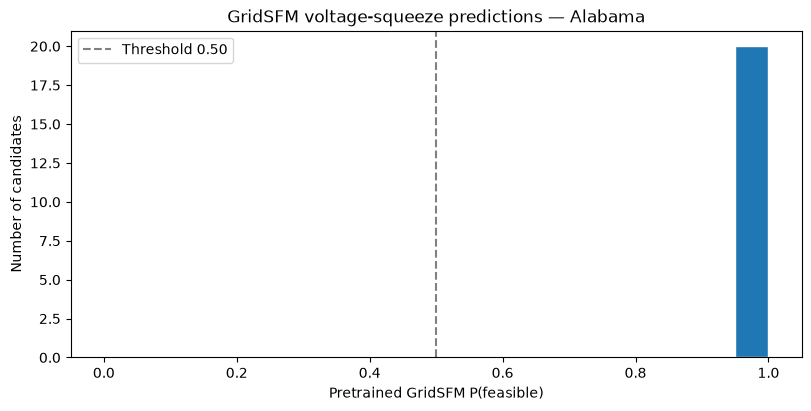

In [6]:
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.hist(model_probs,bins=np.linspace(0,1,21),edgecolor="white")
ax.axvline(MODEL_THRESHOLD,color="gray",linestyle="--",label=f"Threshold {MODEL_THRESHOLD:.2f}")
ax.set(xlabel="Pretrained GridSFM P(feasible)",ylabel="Number of candidates",
       title=f"GridSFM voltage-squeeze predictions — {DATASET_LABEL}")
ax.legend(); fig.savefig(EXPLAIN_ROOT/"model_feasibility_histogram.png",dpi=180,bbox_inches="tight")
plt.show()

## 6. Pick a scenario by GridSFM verdict (not Julia)

In [7]:
FILTERS=["All candidates","Predicted feasible","Predicted infeasible",
         "High confidence feasible (P>=0.9)","High confidence infeasible (P<=0.1)",
         "Near threshold (0.4<=P<=0.6)","Strongest voltage tightening (top 10)"]
def matches_filter(row,label):
    p=row["gridsfm_p_feasible"]
    if label=="All candidates": return True
    if label=="Predicted feasible": return p>=MODEL_THRESHOLD
    if label=="Predicted infeasible": return p<MODEL_THRESHOLD
    if label=="High confidence feasible (P>=0.9)": return p>=.9
    if label=="High confidence infeasible (P<=0.1)": return p<=.1
    if label=="Near threshold (0.4<=P<=0.6)": return .4<=p<=.6
    if label=="Strongest voltage tightening (top 10)":
        top=sorted(model_rows,key=lambda r:r["mean_vmin_tightening_all_buses"]+
                   r["mean_vmax_tightening_all_buses"],reverse=True)[:10]
        return row["candidate_index"] in {r["candidate_index"] for r in top}
    raise ValueError(label)

def describe_candidate(row):
    return (f"#{row['candidate_index']:03d} | iteration {row['iteration']}, sample {row['scenario']} "
            f"| {row['model_category']} | P(feasible)={row['gridsfm_p_feasible']:.4f}")

def show_candidates(filter_name="All candidates",top=40):
    matches=[row for row in model_rows if matches_filter(row,filter_name)]
    print(filter_name,":",len(matches),"candidate(s)")
    for row in matches[:top]: print(" ",describe_candidate(row))
    return matches

try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE=True
except ImportError:
    WIDGETS_AVAILABLE=False

if WIDGETS_AVAILABLE:
    FILTER_WIDGET=widgets.Dropdown(options=FILTERS,value="All candidates",description="Filter:",
                                   layout=widgets.Layout(width="96%"))
    CANDIDATE_WIDGET=widgets.Dropdown(description="Candidate:",layout=widgets.Layout(width="96%"))
    def update_dropdown(change=None):
        matches=[r for r in model_rows if matches_filter(r,FILTER_WIDGET.value)]
        current=CANDIDATE_WIDGET.value
        CANDIDATE_WIDGET.options=([(describe_candidate(r),r["candidate_index"]) for r in matches]
                                   if matches else [("No matches — change filter",None)])
        if current in [r["candidate_index"] for r in matches]:
            CANDIDATE_WIDGET.value=current
    FILTER_WIDGET.observe(update_dropdown,names="value")
    update_dropdown()
    display(widgets.VBox([FILTER_WIDGET,CANDIDATE_WIDGET]))
else:
    print("ipywidgets unavailable; use MANUAL_SCENARIO_INDEX in the next cell.")
show_candidates(top=25)

ipywidgets unavailable; use MANUAL_SCENARIO_INDEX in the next cell.
All candidates : 20 candidate(s)
  #000 | iteration 1, sample 1 | Predicted feasible | P(feasible)=0.9999
  #001 | iteration 1, sample 2 | Predicted feasible | P(feasible)=0.9999
  #002 | iteration 2, sample 1 | Predicted feasible | P(feasible)=0.9999
  #003 | iteration 2, sample 2 | Predicted feasible | P(feasible)=0.9999
  #004 | iteration 3, sample 1 | Predicted feasible | P(feasible)=0.9999
  #005 | iteration 3, sample 2 | Predicted feasible | P(feasible)=0.9992
  #006 | iteration 4, sample 1 | Predicted feasible | P(feasible)=0.9999
  #007 | iteration 4, sample 2 | Predicted feasible | P(feasible)=0.9999
  #008 | iteration 5, sample 1 | Predicted feasible | P(feasible)=0.9999
  #009 | iteration 5, sample 2 | Predicted feasible | P(feasible)=0.9999
  #010 | iteration 6, sample 1 | Predicted feasible | P(feasible)=0.9999
  #011 | iteration 6, sample 2 | Predicted feasible | P(feasible)=0.9998
  #012 | iteration 7, s

[{'candidate_index': 0,
  'iteration': 1,
  'scenario': 1,
  'gridsfm_p_feasible': 0.9999425411224365,
  'gridsfm_p_infeasible': 5.745887756347656e-05,
  'model_category': 'Predicted feasible',
  'n_selected_buses': 49,
  'mean_vmin_tightening_all_buses': 0.0004611086624208838,
  'mean_vmax_tightening_all_buses': 0.0005569810164161026},
 {'candidate_index': 1,
  'iteration': 1,
  'scenario': 2,
  'gridsfm_p_feasible': 0.999941349029541,
  'gridsfm_p_infeasible': 5.8650970458984375e-05,
  'model_category': 'Predicted feasible',
  'n_selected_buses': 49,
  'mean_vmin_tightening_all_buses': 0.00045968839549459517,
  'mean_vmax_tightening_all_buses': 0.0005334598827175796},
 {'candidate_index': 2,
  'iteration': 2,
  'scenario': 1,
  'gridsfm_p_feasible': 0.9999417066574097,
  'gridsfm_p_infeasible': 5.829334259033203e-05,
  'model_category': 'Predicted feasible',
  'n_selected_buses': 49,
  'mean_vmin_tightening_all_buses': 0.0004899532068520784,
  'mean_vmax_tightening_all_buses': 0.0004

## 7. Activate your candidate and choose its explanation target

`EXPLANATION_TARGET="predicted"` explains the **model's predicted class**. Positive SHAP then means *more predicted feasible* on a feasible sample, or *more predicted infeasible* on an infeasible sample.

In [8]:
MANUAL_SCENARIO_INDEX = 0  # Used only if ipywidgets is unavailable
EXPLANATION_TARGET = "predicted"  # "predicted", "feasible", "infeasible"
assert EXPLANATION_TARGET in ("predicted","feasible","infeasible")
if WIDGETS_AVAILABLE:
    if CANDIDATE_WIDGET.value is None:
        raise ValueError("No matching candidate; select another filter")
    SCENARIO_INDEX=int(CANDIDATE_WIDGET.value)
else:
    SCENARIO_INDEX=int(MANUAL_SCENARIO_INDEX)
if not 0 <= SCENARIO_INDEX < len(candidates):
    raise IndexError(f"Candidate {SCENARIO_INDEX} outside 0..{len(candidates)-1}")
chosen_row=model_rows[SCENARIO_INDEX]
chosen=candidates[SCENARIO_INDEX,pyg_to_case_index,:].copy()
delta=chosen-original
p_selected=probability_pygrid(chosen)
TARGET_CLASS=("feasible" if p_selected>=MODEL_THRESHOLD else "infeasible") if EXPLANATION_TARGET=="predicted" else EXPLANATION_TARGET
p_selected_target=p_selected if TARGET_CLASS=="feasible" else 1-p_selected
p_original_target=p_original if TARGET_CLASS=="feasible" else 1-p_original
feasibility_fn=VoltageFeasibilityProbability(TARGET_CLASS).eval()
EXPLAIN_DIR=EXPLAIN_ROOT/f"candidate_{SCENARIO_INDEX:05d}"
EXPLAIN_DIR.mkdir(parents=True,exist_ok=True)
print("Selected:",describe_candidate(chosen_row))
print("Explaining PRETRAINED GridSFM P("+TARGET_CLASS+")")
print(f"Original P({TARGET_CLASS})={p_original_target:.6f}, selected={p_selected_target:.6f}")
print("Selected bus IDs from Gaussian sampling:",selected_bus_ids[SCENARIO_INDEX].tolist())
print("Result folder:",EXPLAIN_DIR)

Selected: #000 | iteration 1, sample 1 | Predicted feasible | P(feasible)=0.9999
Explaining PRETRAINED GridSFM P(feasible)
Original P(feasible)=0.999941, selected=0.999943
Selected bus IDs from Gaussian sampling: ['438', '301', '328', '276', '575', '514', '221', '325', '354', '293', '477', '211', '500', '254', '504', '6', '414', '437', '487', '247', '231', '174', '450', '398', '173', '212', '451', '470', '99', '380', '185', '111', '393', '281', '10', '283', '434', '88', '588', '583', '258', '14', '329', '289', '389', '48', '23', '364', '547']
Result folder: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_voltage_squeeze/alabama/gridsfm_pretrained_voltage_bus_shap/candidate_00000


## 8. Visualize which voltage bounds were actually changed

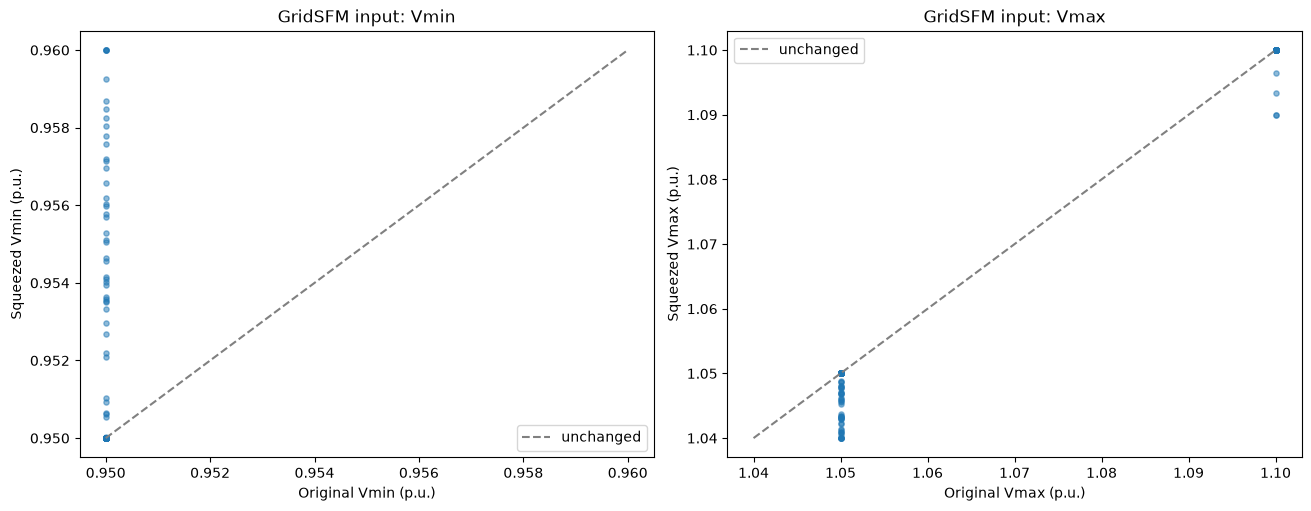

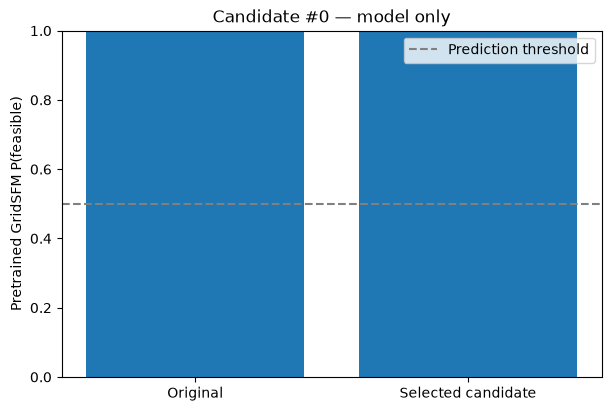

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for j,name in enumerate(("Vmin","Vmax")):
    axes[j].scatter(original[:,j],chosen[:,j],s=14,alpha=.5)
    bounds=[float(min(original[:,j].min(),chosen[:,j].min())),
            float(max(original[:,j].max(),chosen[:,j].max()))]
    axes[j].plot(bounds,bounds,linestyle="--",color="gray",label="unchanged")
    axes[j].set(xlabel=f"Original {name} (p.u.)",ylabel=f"Squeezed {name} (p.u.)",
                title=f"GridSFM input: {name}")
    axes[j].legend()
fig.savefig(EXPLAIN_DIR/"00_original_vs_squeezed_voltage.png",dpi=180,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(6,4),constrained_layout=True)
ax.bar(["Original", "Selected candidate"],[p_original,p_selected])
ax.axhline(MODEL_THRESHOLD,color="gray",linestyle="--",label="Prediction threshold")
ax.set(ylim=(0,1),ylabel="Pretrained GridSFM P(feasible)",
       title=f"Candidate #{SCENARIO_INDEX} — model only")
ax.legend()
fig.savefig(EXPLAIN_DIR/"01_pretrained_probability.png",dpi=180,bbox_inches="tight")
plt.show()

## 9. Whole-grid group Kernel SHAP (Vmin / Vmax)

Compare the *fully original* grid with the selected candidate, grouping buses into up to 12 longitude bands if the case contains coordinates. Otherwise group by PyG bus row and label the groups non-geographically. A group SHAP value is repeated over group members by Captum, so **take the mean** to recover its attribution.

In [10]:
N_GROUPS=min(12,n_pyg_buses)
N_GROUP_SHAP_SAMPLES=128  # Increase to 512/1024 for more stable values (more inference calls)
try:
    longitudes=np.asarray([float(data["bus"][bid]["lon"]) for bid in pyg_bus_ids])
    assert np.isfinite(longitudes).all()
    ordered=np.argsort(longitudes,kind="stable")
    GROUP_LABEL="Band"
    GROUPING_METHOD="longitude_rank_quantiles"
except (KeyError,ValueError,TypeError,AssertionError):
    longitudes=None
    ordered=np.arange(n_pyg_buses)
    GROUP_LABEL="Group"
    GROUPING_METHOD="pyg_bus_row_groups_non_geographic"
    print("Longitude missing: grouping PyG bus rows rather than geographic regions")
group_idx=np.empty(n_pyg_buses,dtype=int)
group_idx[ordered]=(np.arange(n_pyg_buses)*N_GROUPS)//n_pyg_buses
assert len(np.unique(group_idx))==N_GROUPS
feature_mask=np.empty((1,n_pyg_buses,2),dtype=np.int64)
feature_mask[0,:,0]=2*group_idx
feature_mask[0,:,1]=2*group_idx+1

x_input=torch.tensor(chosen[None,:,:],dtype=torch.float32)
x_base=torch.tensor(original[None,:,:],dtype=torch.float32)
shap_t=KernelShap(feasibility_fn).attribute(
    x_input,baselines=x_base,feature_mask=torch.from_numpy(feature_mask),
    n_samples=N_GROUP_SHAP_SAMPLES,perturbations_per_eval=1,show_progress=True)
shap_full=shap_t.squeeze(0).detach().cpu().numpy()
shap_group=np.asarray([[float(shap_full[group_idx==g,j].mean()) for j in range(2)]
                       for g in range(N_GROUPS)])
assert np.isfinite(shap_group).all()
print("Group contributions:",shap_group.shape,"|",GROUPING_METHOD)
print(f"Positive: increases GridSFM P({TARGET_CLASS}); negative: decreases it")
print("Model probability change:",p_selected_target-p_original_target)
print("Sum of group SHAP:",shap_group.sum(),"(approximate; sampling error possible)")

Kernel Shap attribution: 100%|██████████| 128/128 [00:40<00:00,  3.16it/s]


Group contributions: (12, 2) | longitude_rank_quantiles
Positive: increases GridSFM P(feasible); negative: decreases it
Model probability change: 1.0728836059570312e-06
Sum of group SHAP: 1.0728837237516942e-06 (approximate; sampling error possible)


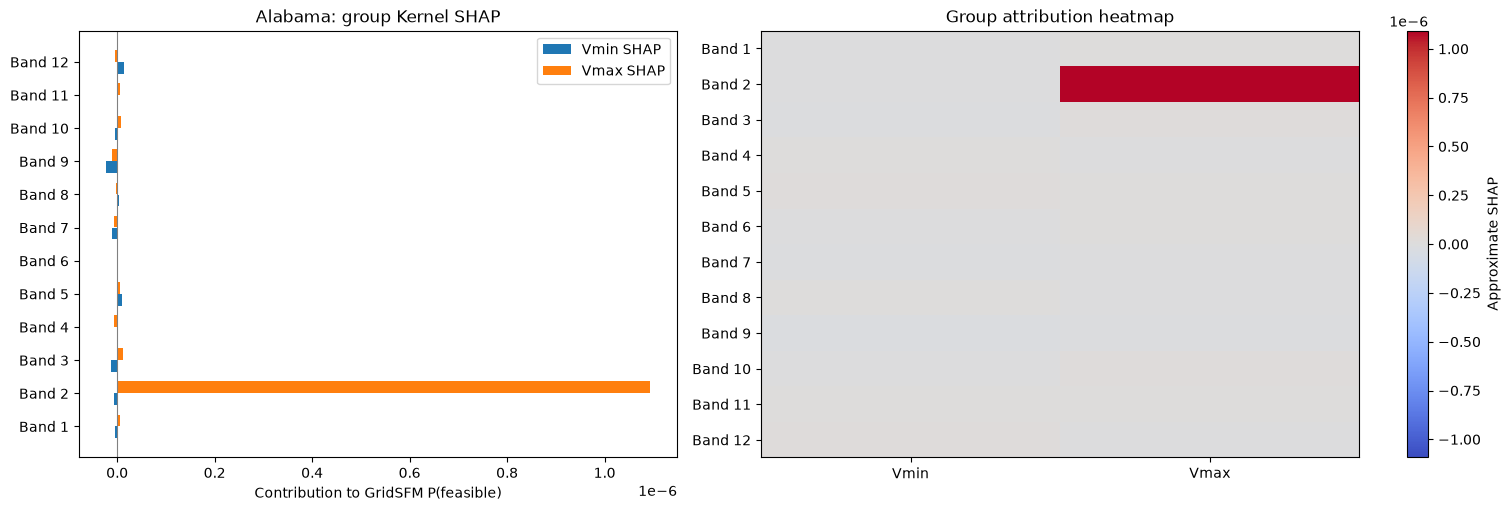

Most influential groups:
{'group': 2, 'group_label': 'Band 2', 'grouping_method': 'longitude_rank_quantiles', 'n_buses': 41, 'vmin_shap': -5.82754999811641e-09, 'vmax_shap': 1.093083483283408e-06, 'total_vmin_change': 0.007740974426269531, 'total_vmax_change': -0.0296783447265625}
{'group': 9, 'group_label': 'Band 9', 'grouping_method': 'longitude_rank_quantiles', 'n_buses': 41, 'vmin_shap': -2.3070368726507695e-08, 'vmax_shap': -1.0273155659490385e-08, 'total_vmin_change': 0.03068643808364868, 'total_vmax_change': -0.04432940483093262}
{'group': 12, 'group_label': 'Band 12', 'grouping_method': 'longitude_rank_quantiles', 'n_buses': 41, 'vmin_shap': 1.4997878494682482e-08, 'vmax_shap': -4.518726726132627e-09, 'total_vmin_change': 0.006697237491607666, 'total_vmax_change': -0.01761019229888916}
{'group': 3, 'group_label': 'Band 3', 'grouping_method': 'longitude_rank_quantiles', 'n_buses': 41, 'vmin_shap': -1.2566498064359166e-08, 'vmax_shap': 1.179102238069163e-08, 'total_vmin_change': 

In [11]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
ys=np.arange(N_GROUPS)
labels=[f"{GROUP_LABEL} {g+1}" for g in ys]
ax1.barh(ys-.18,shap_group[:,0],height=.35,label="Vmin SHAP")
ax1.barh(ys+.18,shap_group[:,1],height=.35,label="Vmax SHAP")
ax1.axvline(0,color="gray",lw=.8)
ax1.set_yticks(ys,labels)
ax1.set_xlabel(f"Contribution to GridSFM P({TARGET_CLASS})")
ax1.set_title(f"{DATASET_LABEL}: group Kernel SHAP")
ax1.legend()
bound=max(1e-8,float(np.abs(shap_group).max()))
im=ax2.imshow(shap_group,cmap="coolwarm",aspect="auto",vmin=-bound,vmax=bound)
ax2.set_xticks([0,1],["Vmin","Vmax"])
ax2.set_yticks(ys,labels)
ax2.set_title("Group attribution heatmap")
fig.colorbar(im,ax=ax2,label="Approximate SHAP")
fig.savefig(EXPLAIN_DIR/"02_group_shap.png",dpi=180,bbox_inches="tight")
plt.show()

group_rows=[]
for g in range(N_GROUPS):
    group_rows.append(dict(group=g+1,group_label=labels[g],grouping_method=GROUPING_METHOD,
                           n_buses=int((group_idx==g).sum()),
                           vmin_shap=float(shap_group[g,0]),vmax_shap=float(shap_group[g,1]),
                           total_vmin_change=float(delta[group_idx==g,0].sum()),
                           total_vmax_change=float(delta[group_idx==g,1].sum())))
print("Most influential groups:")
for r in sorted(group_rows,key=lambda r:max(abs(r["vmin_shap"]),abs(r["vmax_shap"])),reverse=True)[:8]:
    print(r)

## 10. Focused **bus-level** Kernel SHAP

Select up to 8 **changed buses** from the strongest global groups and explain their Vmin/Vmax effects separately. You may override bus selection using `MANUAL_BUS_IDS`.

**This is conditional SHAP:** all other candidate buses stay at their perturbed values. Its baseline reverts only the selected buses to their original voltage limits. Therefore these bus-level values need not sum to the full-grid probability difference or match group SHAP exactly.

In [12]:
BUS_SHAP_TOP_GROUPS=2
BUS_SHAP_MAX_BUSES=8
N_BUS_SHAP_SAMPLES=256
MANUAL_BUS_IDS=None  # e.g. ["403", "15"] — must match validated PyG bus IDs

pyg_bus_index={bid:i for i,bid in enumerate(pyg_bus_ids)}
changed_rows=np.flatnonzero(np.any(np.abs(delta)>1e-8,axis=1))
if len(changed_rows)==0:
    raise RuntimeError("Selected candidate did not change any PyG bus voltage limits")
if MANUAL_BUS_IDS is not None:
    chosen_bus_ids=list(dict.fromkeys(str(b) for b in MANUAL_BUS_IDS))
    missing=[b for b in chosen_bus_ids if b not in pyg_bus_index]
    if missing: raise ValueError(f"Unknown PyG bus ID(s): {missing}")
    selected_rows=np.asarray([pyg_bus_index[b] for b in chosen_bus_ids],dtype=int)
else:
    ranks=np.argsort(np.max(np.abs(shap_group),axis=1))[::-1]
    top_groups=set(ranks[:BUS_SHAP_TOP_GROUPS])
    shortlist=np.asarray([r for r in changed_rows if group_idx[r] in top_groups],dtype=int)
    if len(shortlist)==0: shortlist=changed_rows
    strength=np.abs(delta[shortlist]).sum(axis=1)
    selected_rows=shortlist[np.argsort(strength)[::-1][:BUS_SHAP_MAX_BUSES]]
    chosen_bus_ids=[pyg_bus_ids[int(r)] for r in selected_rows]
assert len(selected_rows)>0 and len(set(selected_rows.tolist()))==len(selected_rows)

# Inputs to Captum are ONLY selected-bus features. All other candidate bus
# limits stay fixed; this makes individual-bus effects estimable without
# introducing an artificial 'all unselected buses' SHAP feature.
class FocusedBusModel(torch.nn.Module):
    def forward(self,batch_selected):
        rows=batch_selected.detach().cpu().numpy()
        pred=[]
        for values in rows:
            full=chosen.copy()
            full[selected_rows]=values
            p=probability_pygrid(full)
            pred.append(p if TARGET_CLASS=="feasible" else 1-p)
        return torch.as_tensor(pred,dtype=torch.float32,device=batch_selected.device)

bus_input=torch.tensor(chosen[selected_rows][None,:,:],dtype=torch.float32)
bus_baseline=torch.tensor(original[selected_rows][None,:,:],dtype=torch.float32)
focused_model=FocusedBusModel().eval()
# Each selected bus boundary is its own SHAP feature (2 per bus).
bus_shap_t=KernelShap(focused_model).attribute(
    bus_input,baselines=bus_baseline,n_samples=N_BUS_SHAP_SAMPLES,
    perturbations_per_eval=1,show_progress=True)
bus_shap=bus_shap_t.squeeze(0).detach().cpu().numpy()
assert bus_shap.shape==(len(selected_rows),2) and np.isfinite(bus_shap).all()
conditional_baseline=chosen.copy()
conditional_baseline[selected_rows]=original[selected_rows]
p_conditional=probability_pygrid(conditional_baseline)
p_conditional_target=p_conditional if TARGET_CLASS=="feasible" else 1-p_conditional
print("Bus IDs explained:",chosen_bus_ids)
print(f"Conditional model probability difference: {p_selected_target-p_conditional_target:+.6f}")
print(f"Sum of bus SHAP (approx.): {bus_shap.sum():+.6f}")

Kernel Shap attribution: 100%|██████████| 256/256 [01:18<00:00,  3.25it/s]


Bus IDs explained: ['289', '434', '276', '500', '301', '437', '575', '438']
Conditional model probability difference: +0.000000
Sum of bus SHAP (approx.): +0.000000


Bus-level Kernel SHAP ranking (model explanation, not solver proof):
{'bus_id': '289', 'bus_name': 'BUS_289', 'original_vmin': 0.949999988079071, 'new_vmin': 0.9540237188339233, 'delta_vmin': 0.004023730754852295, 'original_vmax': 1.0499999523162842, 'new_vmax': 1.0399999618530273, 'delta_vmax': -0.009999990463256836, 'vmin_shap': 0.0, 'vmax_shap': 0.0, 'abs_total_shap': 0.0}
{'bus_id': '434', 'bus_name': 'BUS_434', 'original_vmin': 0.949999988079071, 'new_vmin': 0.953948438167572, 'delta_vmin': 0.0039484500885009766, 'original_vmax': 1.0499999523162842, 'new_vmax': 1.0405036211013794, 'delta_vmax': -0.009496331214904785, 'vmin_shap': 0.0, 'vmax_shap': 0.0, 'abs_total_shap': 0.0}
{'bus_id': '276', 'bus_name': 'Opp Substation', 'original_vmin': 0.949999988079071, 'new_vmin': 0.9535956382751465, 'delta_vmin': 0.0035956501960754395, 'original_vmax': 1.0499999523162842, 'new_vmax': 1.0429335832595825, 'delta_vmax': -0.00706636905670166, 'vmin_shap': 0.0, 'vmax_shap': 0.0, 'abs_total_shap':

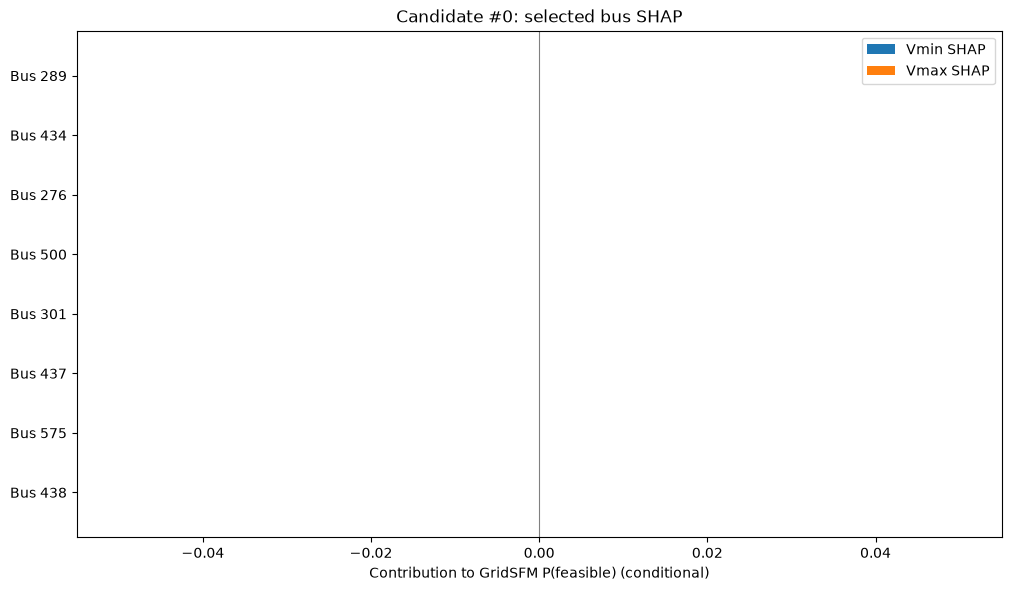

In [13]:
bus_rows=[]
for j,bid in enumerate(chosen_bus_ids):
    r=int(selected_rows[j])
    bus_rows.append(dict(bus_id=str(bid),bus_name=str(data["bus"][bid].get("name","")),
                         original_vmin=float(original[r,0]),new_vmin=float(chosen[r,0]),
                         delta_vmin=float(delta[r,0]),
                         original_vmax=float(original[r,1]),new_vmax=float(chosen[r,1]),
                         delta_vmax=float(delta[r,1]),
                         vmin_shap=float(bus_shap[j,0]),vmax_shap=float(bus_shap[j,1]),
                         abs_total_shap=float(np.abs(bus_shap[j]).sum())))
bus_rows.sort(key=lambda r:r["abs_total_shap"],reverse=True)
print("Bus-level Kernel SHAP ranking (model explanation, not solver proof):")
for r in bus_rows: print(r)

fig,ax=plt.subplots(figsize=(10,max(4,.6*len(bus_rows)+1)),constrained_layout=True)
ys=np.arange(len(bus_rows))
ax.barh(ys-.19,[r["vmin_shap"] for r in bus_rows],height=.36,label="Vmin SHAP")
ax.barh(ys+.19,[r["vmax_shap"] for r in bus_rows],height=.36,label="Vmax SHAP")
ax.set_yticks(ys,[f"Bus {r['bus_id']}" for r in bus_rows])
ax.invert_yaxis();ax.axvline(0,color="gray",lw=.8)
ax.set_xlabel(f"Contribution to GridSFM P({TARGET_CLASS}) (conditional)")
ax.set_title(f"Candidate #{SCENARIO_INDEX}: selected bus SHAP")
ax.legend();fig.savefig(EXPLAIN_DIR/"03_bus_shap.png",dpi=180,bbox_inches="tight")
plt.show()

## 11. Export model prediction, group SHAP, and bus SHAP

In [14]:
def write_csv(path,records):
    if not records: return
    with Path(path).open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=list(records[0]))
        w.writeheader();w.writerows(records)

write_csv(EXPLAIN_DIR/"group_voltage_shap.csv",group_rows)
write_csv(EXPLAIN_DIR/"bus_voltage_shap.csv",bus_rows)
info=dict(dataset=DATASET_NAME,candidate_index=SCENARIO_INDEX,
          iteration=chosen_row["iteration"],scenario=chosen_row["scenario"],
          gridsfm_p_feasible=float(p_selected),
          gridsfm_verdict=chosen_row["model_category"],
          explanation_target=TARGET_CLASS,
          original_target_probability=float(p_original_target),
          selected_target_probability=float(p_selected_target),
          grouping_method=GROUPING_METHOD,
          selected_bus_ids=chosen_bus_ids,
          conditionally_reverted_only_these_buses=True,
          checkpoint=str(CHECKPOINT_PATH),pyg_graph=str(PYG_PATH),
          source_case_sha256=CASE_SHA256)
with (EXPLAIN_DIR/"explanation_summary.json").open("w",encoding="utf-8") as f:
    json.dump(info,f,indent=2)
print("Saved model predictions for every candidate:",EXPLAIN_ROOT/"pretrained_model_predictions.csv")
print("Saved selected candidate's explanations:",EXPLAIN_DIR)

Saved model predictions for every candidate: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_voltage_squeeze/alabama/gridsfm_pretrained_voltage_bus_shap/pretrained_model_predictions.csv
Saved selected candidate's explanations: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_voltage_squeeze/alabama/gridsfm_pretrained_voltage_bus_shap/candidate_00000


## Interpretation and limitations

- **Model predicts feasible** if `P(feasible) >= MODEL_THRESHOLD`; otherwise it predicts infeasible. This is a learned probability-like output and may be miscalibrated.
- `EXPLANATION_TARGET="predicted"` always explains the class the pretrained model predicted, **not Julia's sampling label**.
- A positive Vmin/Vmax SHAP value increases the explained model-class probability relative to the stated baseline; a negative value decreases it. It does **not** mean the physical bound itself increased or decreased.
- **Group SHAP** uses the completely original grid as baseline and explains up to 12 groups. **Bus-level SHAP** is conditional on all *other candidate buses remaining perturbed*. Interpret rankings in that context.
- Kernel SHAP is stochastic/approximate and can be unstable when sample counts are small. Increase `N_GROUP_SHAP_SAMPLES` and `N_BUS_SHAP_SAMPLES` and repeat important candidate explanations before making claims.
- The selected subset of buses is not a verified ranking of every bus. You can choose specific bus IDs via `MANUAL_BUS_IDS`.
- The ability to explain Vmin/Vmax follows from the original GridSFM bus schema, but only when your saved candidates and PyG graph map correctly; the notebook checks both against your raw model JSON.
- Solver nonacceptance during sampling is not automatically a mathematical proof of physical infeasibility; this notebook **does not use it to decide feasibility**.